# Predicting Undergraduate Student Dropout

Can we create a model that predicts whether a student will drop out based on their socioeconomic and academic data? Using 4,424 undergraduate students, we compare dropouts against graduates (students still enrolled are excluded, since their outcome is unknown). Logistic regression, random forest and XGBoost are each built as a baseline and a tuned model, selected by PR-AUC.

**Priority:** a missed dropout costs far more than an extra counselor meeting, so the decision threshold is set to catch at least 90% of dropouts.

In [73]:
import pandas as pd

df = pd.read_csv("../data/undergraduate_student_dropout.csv", sep=";")
df.columns = df.columns.str.strip()   # one column name has a stray tab at the end
df.head()


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Dropping students who are enrolled because they may drop out later, only keeping dropout and graduate, making it a binary problem. 

In [74]:
# Keep only students with a known final outcome (drop those still enrolled)
df = df[df["Target"] != "Enrolled"].copy()

# Binary target: 1 = Dropout, 0 = Graduate
df["Dropout"] = (df["Target"] == "Dropout").astype(int)
df = df.drop(columns="Target")

print(f"Rows: {len(df):,}")
print(df["Dropout"].value_counts().rename({0: "Graduate (0)", 1: "Dropout (1)"}))
print(f"Dropout rate: {df['Dropout'].mean():.1%}")

Rows: 3,630
Dropout
Graduate (0)    2209
Dropout (1)     1421
Name: count, dtype: int64
Dropout rate: 39.1%


152 students have 0 curricular units enrolled in both semesters (and 0 credited). All 152 are in the same course, Animation and Multimedia Design (code 171), and half of them (75) graduated, which is impossible with no units enrolled. This means the academic data for that course is missing and was recorded as 0, not that these students left early. Keeping them would teach the model that "0 units" means nothing in particular, and would distort the semester rates and averages, so we drop these 152 students. Only 26 students remain in Animation and Multimedia Design after this.

In [75]:
# Students with 0 units enrolled in BOTH semesters (missing academic records, not real zeros)
zero_units = ((df["Curricular units 1st sem (enrolled)"] == 0) &
              (df["Curricular units 2nd sem (enrolled)"] == 0))

print(f"Students with 0 units enrolled in both semesters: {zero_units.sum()}")
print("\nTheir course:")
print(df.loc[zero_units, "Course"].value_counts().to_string())
print("\nTheir outcome:")
print(df.loc[zero_units, "Dropout"].value_counts().rename({0: "Graduate (0)", 1: "Dropout (1)"}).to_string())

df = df[~zero_units].copy()
print(f"\nRows after dropping: {len(df):,}   Dropout rate: {df['Dropout'].mean():.1%}")

Students with 0 units enrolled in both semesters: 152

Their course:
Course
171    152

Their outcome:
Dropout
Dropout (1)     77
Graduate (0)    75

Rows after dropping: 3,478   Dropout rate: 38.6%


After removing the students with missing academic records, two courses fall below the 30-student threshold (about 1% of the training set): Animation and Multimedia Design (26 students) and Biofuel Production Technologies (9 students). With so few students, the model cannot learn anything reliable about them on their own, so instead of dropping these students we merge each course into its closest related course: Biofuel Production Technologies into Agronomy (both agricultural/technical), and Animation and Multimedia Design into Communication Design (both design courses).

In [76]:
# Merge courses with fewer than 30 students into their closest related course
course_merges = {
    33:  9003,   # Biofuel Production Technologies -> Agronomy
    171: 9070,   # Animation and Multimedia Design  -> Communication Design
}
print("Before merging:")
print(df["Course"].value_counts()[list(course_merges) + list(course_merges.values())].to_string())

df["Course"] = df["Course"].replace(course_merges)

print("\nAfter merging:")
print(df["Course"].value_counts()[list(course_merges.values())].to_string())
print(f"\nRows: {len(df):,}   Courses: {df['Course'].nunique()}   Smallest course: {df['Course'].value_counts().min()} students")

Before merging:
Course
33        9
171      26
9003    173
9070    184

After merging:
Course
9003    182
9070    210

Rows: 3,478   Courses: 15   Smallest course: 69 students


The categorical variables are encoded as numerical variables already. From the documentation, here is a key of the numerical variables to categorical variables. 

In [77]:
# Code -> meaning for each categorical variable (from the dataset documentation)
qualification_codes = {
    1: "Secondary education - 12th year or equiv.", 2: "Higher education - bachelor's degree",
    3: "Higher education - degree", 4: "Higher education - master's", 5: "Higher education - doctorate",
    6: "Frequency of higher education", 9: "12th year of schooling - not completed",
    10: "11th year of schooling - not completed", 11: "7th year (old)", 12: "Other - 11th year of schooling",
    13: "2nd year complementary high school course", 14: "10th year of schooling", 15: "10th year of schooling - not completed",
    18: "General commerce course", 19: "Basic education 3rd cycle (9th/10th/11th year) or equiv.",
    20: "Complementary high school course", 22: "Technical-professional course",
    25: "Complementary high school course - not concluded", 26: "7th year of schooling",
    27: "2nd cycle of the general high school course", 29: "9th year of schooling - not completed",
    30: "8th year of schooling", 31: "General course of administration and commerce",
    33: "Supplementary accounting and administration", 34: "Unknown", 35: "Can't read or write",
    36: "Can read without having a 4th year of schooling", 37: "Basic education 1st cycle (4th/5th year) or equiv.",
    38: "Basic education 2nd cycle (6th/7th/8th year) or equiv.", 39: "Technological specialization course",
    40: "Higher education - degree (1st cycle)", 41: "Specialized higher studies course",
    42: "Professional higher technical course", 43: "Higher education - master (2nd cycle)",
    44: "Higher education - doctorate (3rd cycle)",
}

occupation_codes = {
    0: "Student", 1: "Legislative/executive representatives, directors and executive managers",
    2: "Specialists in intellectual and scientific activities", 3: "Intermediate-level technicians and professions",
    4: "Administrative staff", 5: "Personal services, security and safety workers and sellers",
    6: "Farmers and skilled workers in agriculture, fisheries and forestry",
    7: "Skilled workers in industry, construction and craftsmen", 8: "Installation and machine operators and assembly workers",
    9: "Unskilled workers", 10: "Armed forces professions", 90: "Other situation", 99: "(blank)",
    101: "Armed forces officers", 102: "Armed forces sergeants", 103: "Other armed forces personnel",
    112: "Directors of administrative and commercial services", 114: "Hotel, catering, trade and other services directors",
    121: "Specialists in physical sciences, mathematics, engineering and related", 122: "Health professionals",
    123: "Teachers", 124: "Specialists in finance, accounting, administration, public and commercial relations",
    125: "Specialists in information and communication technologies (ICT)",
    131: "Intermediate-level science and engineering technicians", 132: "Intermediate-level health technicians and professionals",
    134: "Intermediate-level technicians in legal, social, sports, cultural and similar services",
    135: "Information and communication technology technicians",
    141: "Office workers, secretaries and data processing operators",
    143: "Data, accounting, statistical, financial services and registry operators", 144: "Other administrative support staff",
    151: "Personal service workers", 152: "Sellers", 153: "Personal care workers and the like",
    154: "Protection and security services personnel",
    161: "Market-oriented farmers and skilled agricultural and animal production workers",
    163: "Subsistence farmers, livestock keepers, fishermen, hunters and gatherers",
    171: "Skilled construction workers and the like, except electricians",
    172: "Skilled workers in metallurgy, metalworking and similar",
    173: "Skilled workers in printing, precision instruments, jewelers, artisans and the like",
    174: "Skilled workers in electricity and electronics",
    175: "Workers in food processing, woodworking, clothing and other industries and crafts",
    181: "Fixed plant and machine operators", 182: "Assembly workers", 183: "Vehicle drivers and mobile equipment operators",
    191: "Cleaning workers", 192: "Unskilled workers in agriculture, animal production, fisheries and forestry",
    193: "Unskilled workers in extractive industry, construction, manufacturing and transport",
    194: "Meal preparation assistants", 195: "Street vendors (except food) and street service providers",
}

code_maps = {
    "Marital status": {1: "Single", 2: "Married", 3: "Widower", 4: "Divorced", 5: "Facto union", 6: "Legally separated"},
    "Application mode": {
        1: "1st phase - general contingent", 2: "Ordinance No. 612/93",
        5: "1st phase - special contingent (Azores Island)", 7: "Holders of other higher courses",
        10: "Ordinance No. 854-B/99", 15: "International student (bachelor)",
        16: "1st phase - special contingent (Madeira Island)", 17: "2nd phase - general contingent",
        18: "3rd phase - general contingent", 26: "Ordinance No. 533-A/99, item b2 (different plan)",
        27: "Ordinance No. 533-A/99, item b3 (other institution)", 39: "Over 23 years old", 42: "Transfer",
        43: "Change of course", 44: "Technological specialization diploma holders",
        51: "Change of institution/course", 53: "Short cycle diploma holders",
        57: "Change of institution/course (international)",
    },
    "Course": {
        33: "Biofuel Production Technologies", 171: "Animation and Multimedia Design",
        8014: "Social Service (evening attendance)", 9003: "Agronomy", 9070: "Communication Design",
        9085: "Veterinary Nursing", 9119: "Informatics Engineering", 9130: "Equinculture", 9147: "Management",
        9238: "Social Service", 9254: "Tourism", 9500: "Nursing", 9556: "Oral Hygiene",
        9670: "Advertising and Marketing Management", 9773: "Journalism and Communication",
        9853: "Basic Education", 9991: "Management (evening attendance)",
    },
    "Previous qualification": qualification_codes,
    "Nacionality": {
        1: "Portuguese", 2: "German", 6: "Spanish", 11: "Italian", 13: "Dutch", 14: "English", 17: "Lithuanian",
        21: "Angolan", 22: "Cape Verdean", 24: "Guinean", 25: "Mozambican", 26: "Santomean", 32: "Turkish",
        41: "Brazilian", 62: "Romanian", 100: "Moldovan", 101: "Mexican", 103: "Ukrainian", 105: "Russian",
        108: "Cuban", 109: "Colombian",
    },
    "Mother's qualification": qualification_codes,
    "Father's qualification": qualification_codes,
    "Mother's occupation": occupation_codes,
    "Father's occupation": occupation_codes,
    "Daytime/evening attendance": {1: "Daytime", 0: "Evening"},
    "Gender": {1: "Male", 0: "Female"},
}
# Yes/no columns (1 = yes, 0 = no): Displaced, Educational special needs, Debtor,
# Tuition fees up to date, Scholarship holder, International

# One table per variable: code, meaning, and how many students have that code
for col, mapping in code_maps.items():
    counts = df[col].value_counts()
    key = pd.DataFrame({
        "Code": counts.index,
        "Meaning": [mapping.get(c, "(not in documentation)") for c in counts.index],
        "Students": counts.values,
    }).sort_values("Code").reset_index(drop=True)
    print(f"\n{col}  ({len(key)} codes in the data)")
    display(key.style.hide(axis="index"))


Marital status  (6 codes in the data)


Code,Meaning,Students
1,Single,3050
2,Married,324
3,Widower,2
4,Divorced,75
5,Facto union,22
6,Legally separated,5



Application mode  (18 codes in the data)


Code,Meaning,Students
1,1st phase - general contingent,1308
2,Ordinance No. 612/93,3
5,1st phase - special contingent (Azores Island),8
7,Holders of other higher courses,130
10,Ordinance No. 854-B/99,10
15,International student (bachelor),20
16,1st phase - special contingent (Madeira Island),27
17,2nd phase - general contingent,691
18,3rd phase - general contingent,106
26,"Ordinance No. 533-A/99, item b2 (different plan)",1



Course  (15 codes in the data)


Code,Meaning,Students
8014,Social Service (evening attendance),194
9003,Agronomy,182
9070,Communication Design,210
9085,Veterinary Nursing,262
9119,Informatics Engineering,106
9130,Equinculture,120
9147,Management,272
9238,Social Service,313
9254,Tourism,211
9500,Nursing,666


... (12 outputs left out)


Daytime/evening attendance  (2 codes in the data)


Code,Meaning,Students
0,Evening,408
1,Daytime,3070



Gender  (2 codes in the data)


Code,Meaning,Students
0,Female,2315
1,Male,1163


There's a lot of categories with just a few values. Using judgement, the next step is to group them together into sensible categories. However, even after grouping, if a category has fewer than 30 students (about 1% of the training set after an 80/20 split), we will merge it into a related category. It is very difficult to group the occupations together, and low, medium, or high will be based on assumptions. Unknown and other categories will be kept as a separate category. 

In [78]:
def to_code_map(groups):
    """{"Group": [codes]} -> {code: "Group"}"""
    return {code: group for group, codes in groups.items() for code in codes}

education_groups = {     # parents' education (code 34 = Unknown)
    "Low":     [9, 10, 11, 12, 13, 14, 15, 19, 25, 26, 29, 30, 35, 36, 37, 38],
    "Medium":  [1, 6, 18, 20, 22, 27, 31, 33, 39, 42],
    "High":    [2, 3, 4, 5, 40, 41, 43, 44],
    "Unknown": [34],
}
occupation_groups = {    # parents' occupation, by skill level
    "High skill":   [1, 2, 3, 112, 114, 121, 122, 123, 124, 125, 131, 132, 134, 135],
    "Medium skill": [4, 5, 6, 7, 8, 10, 101, 102, 103, 141, 143, 144, 151, 152, 153, 154, 161,
                     171, 172, 173, 174, 175, 181, 182, 183],
    "Low skill":    [9, 163, 191, 192, 193, 194, 195],
    "Other":        [0, 90, 99],     # student, other situation, blank
}

group_maps = {
    "Marital status": {
        "Single":  [1],
        "Married": [2],
        "Other":   [3, 4, 5, 6],     # widower, divorced, facto union, legally separated
    },
    "Application mode": {
        "1st phase (general)":             [1],
        "2nd/3rd phase (general)":         [17, 18],
        "Over 23":                         [39],
        "Transfer / change of course":     [42, 43, 51, 57],
        "Holders of other qualifications": [7, 44, 53],
        "Special / other":                 [2, 5, 10, 15, 16, 26, 27],
    },
    "Previous qualification": {
        "Low":    [9, 10, 12, 14, 15, 19, 38],
        "Medium": [1, 6, 39, 42],
        "High":   [2, 3, 4, 5, 40, 43],
    },
    "Mother's qualification": education_groups,
    "Father's qualification": education_groups,
    "Mother's occupation":    occupation_groups,
    "Father's occupation":    occupation_groups,
}

for col, groups in group_maps.items():
    grouped = df[col].map(to_code_map(groups))
    unmapped = sorted(df.loc[grouped.isna(), col].unique())
    assert not unmapped, f"{col}: codes without a group: {unmapped}"

    # Table: each group, the original codes in it, and how many students
    key = (pd.DataFrame({"Group": grouped, "Code": df[col]})
             .groupby("Group")
             .agg(Codes=("Code", lambda s: ", ".join(str(c) for c in sorted(s.unique()))),
                  Students=("Code", "size"))
             .reindex(list(groups))           # keep the order defined above
             .reset_index())
    print(f"\n{col}  ->  {len(key)} groups")
    display(key.style.hide(axis="index"))

    df[f"{col} (grouped)"] = grouped
    df = df.drop(columns=col)

# Nationality: Portuguese vs non-Portuguese is identical to the International column, so drop it
df = df.drop(columns="Nacionality")



Marital status  ->  3 groups


Group,Codes,Students
Single,1,3050
Married,2,324
Other,"3, 4, 5, 6",104



Application mode  ->  6 groups


Group,Codes,Students
1st phase (general),1,1308
2nd/3rd phase (general),"17, 18",797
Over 23,39,655
Transfer / change of course,"42, 43, 51, 57",341
Holders of other qualifications,"7, 44, 53",307
Special / other,"2, 5, 10, 15, 16, 26, 27",70



Previous qualification  ->  3 groups


Group,Codes,Students
Low,"9, 10, 12, 14, 15, 19, 38",209
Medium,"1, 6, 39, 42",3080
High,"2, 3, 4, 5, 40, 43",189


... (4 outputs left out)


Mother's occupation  ->  4 groups


Group,Codes,Students
High skill,"1, 2, 3, 123, 125, 132, 134",574
Medium skill,"4, 5, 6, 7, 8, 10, 141, 143, 144, 151, 152, 153, 171, 175",1392
Low skill,"9, 191, 192, 193, 194",1286
Other,"0, 90, 99",226



Father's occupation  ->  4 groups


Group,Codes,Students
High skill,"1, 2, 3, 112, 114, 122, 123, 124, 131, 135",548
Medium skill,"4, 5, 6, 7, 8, 10, 101, 102, 103, 141, 143, 144, 151, 152, 153, 154, 171, 172, 174, 175, 181, 182, 183",1901
Low skill,"9, 163, 192, 193, 194, 195",823
Other,"0, 90, 99",206


Overall dropout rate: 38.6% (1,344 of 3,478 students)


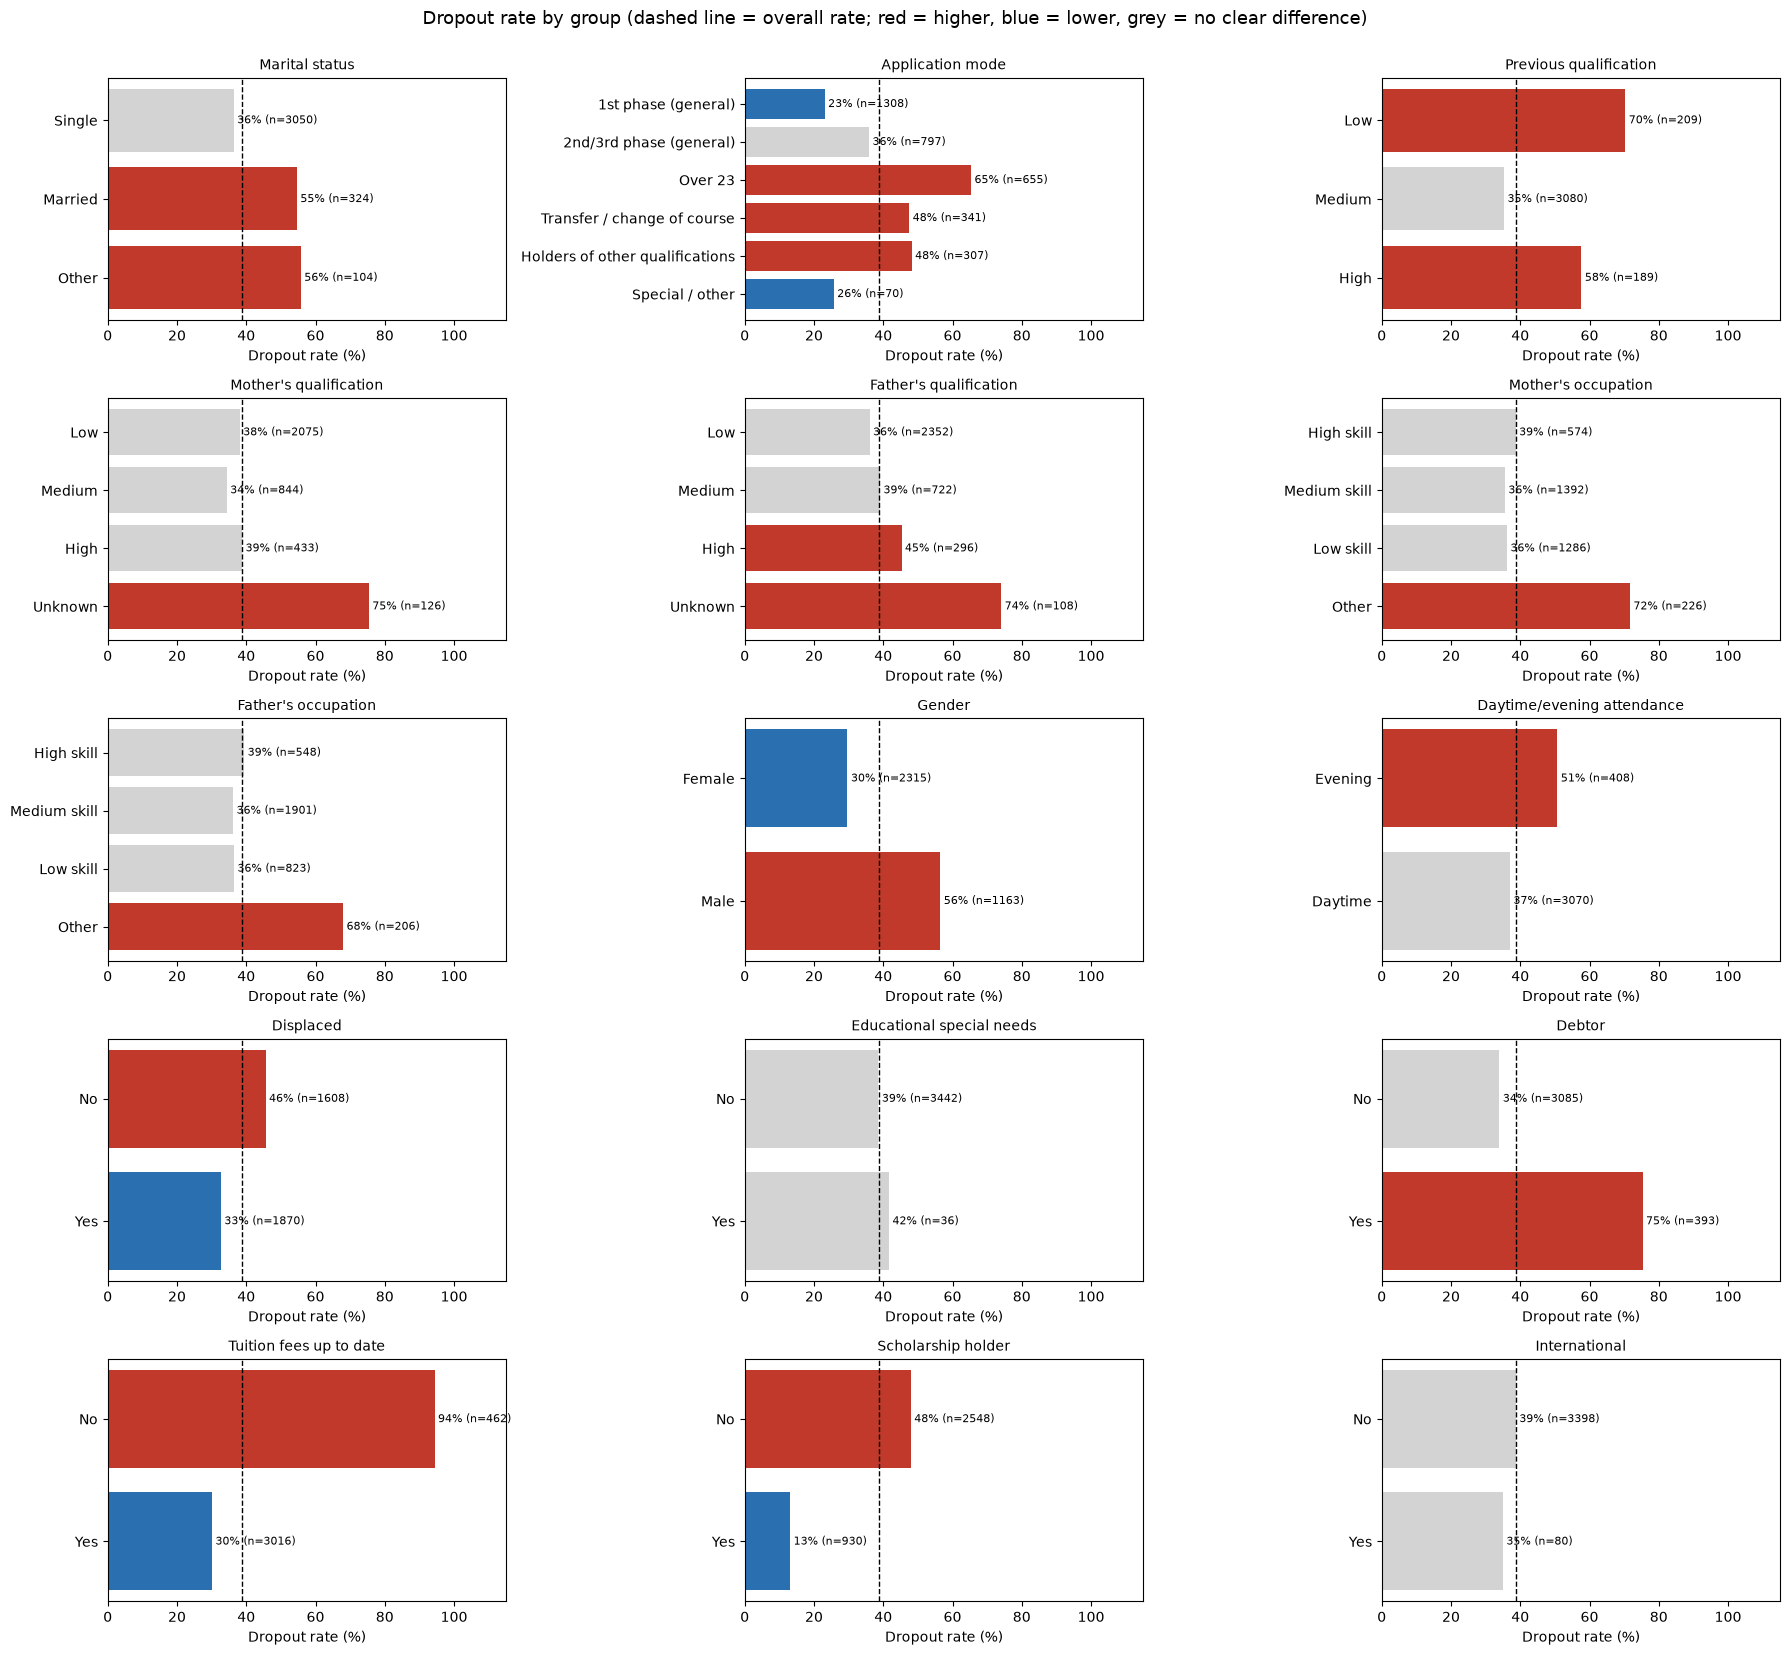

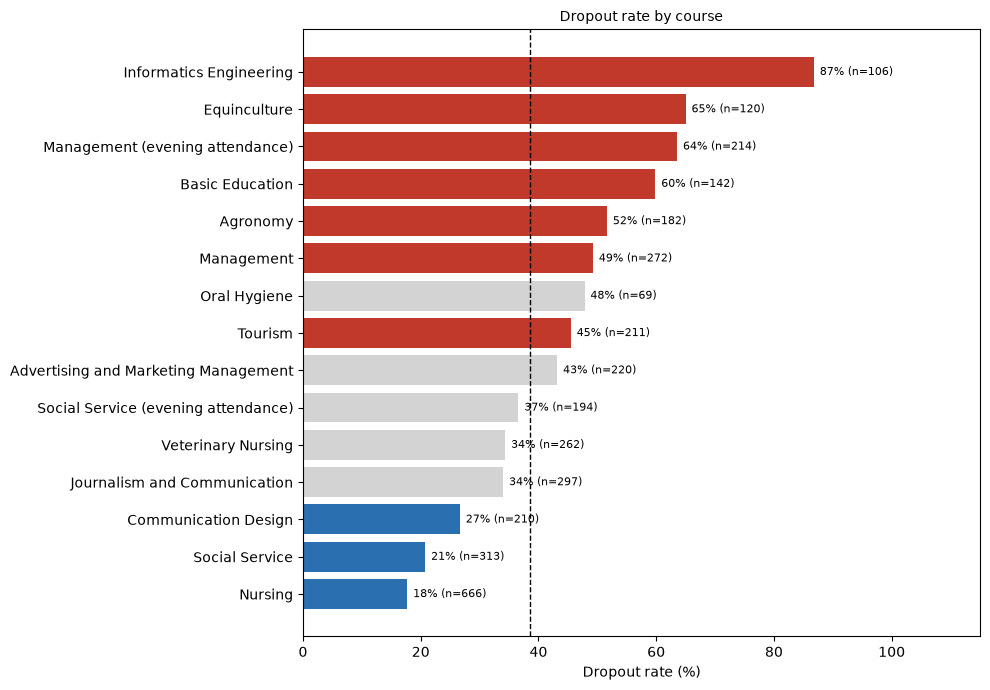

34 groups stand out:


,,n,Dropout rate,vs overall (pp)
Variable,Group,,,
Tuition fees up to date,No,462,94%,55.7
Course,Informatics Engineering,106,87%,48.1
Mother's qualification,Unknown,126,75%,36.8
Debtor,Yes,393,75%,36.7
Father's qualification,Unknown,108,74%,35.4
Mother's occupation,Other,226,72%,33.0
Previous qualification,Low,209,70%,31.7
Father's occupation,Other,206,68%,29.3
Application mode,Over 23,655,65%,26.7


In [79]:
import numpy as np
import matplotlib.pyplot as plt

overall = df["Dropout"].mean()
print(f"Overall dropout rate: {overall:.1%} ({df['Dropout'].sum():,} of {len(df):,} students)")

def dropout_by_group(col, order=None, labels=None):
    """Dropout rate and size per group; flags groups that clearly differ from the overall rate."""
    t = df.groupby(col)["Dropout"].agg(rate="mean", n="size")
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    if labels is not None:
        t.index = [labels.get(i, i) for i in t.index]
    se = np.sqrt(overall * (1 - overall) / t["n"])        # standard error of a group's rate
    t["diff"] = t["rate"] - overall
    # Stands out: statistically different from the overall rate AND at least 5 percentage points away
    t["stands_out"] = (t["diff"].abs() / se > 1.96) & (t["diff"].abs() >= 0.05)
    return t

def plot_rates(ax, t, title):
    colors = np.where(~t["stands_out"], "lightgrey", np.where(t["diff"] > 0, "#c0392b", "#2a6fb0"))
    ax.barh([str(i) for i in t.index], t["rate"] * 100, color=colors)
    ax.axvline(overall * 100, color="black", ls="--", lw=1)
    for y, (rate, n) in enumerate(zip(t["rate"], t["n"])):
        ax.text(rate * 100 + 1, y, f"{rate:.0%} (n={n})", va="center", fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 115)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Dropout rate (%)")

binary_labels = {
    "Gender":                     {0: "Female", 1: "Male"},
    "Daytime/evening attendance": {0: "Evening", 1: "Daytime"},
    "Displaced":                  {0: "No", 1: "Yes"},
    "Educational special needs":  {0: "No", 1: "Yes"},
    "Debtor":                     {0: "No", 1: "Yes"},
    "Tuition fees up to date":    {0: "No", 1: "Yes"},
    "Scholarship holder":         {0: "No", 1: "Yes"},
    "International":              {0: "No", 1: "Yes"},
}
variables = {f"{c} (grouped)": (list(groups), None) for c, groups in group_maps.items()}
variables.update({c: ([0, 1], labels) for c, labels in binary_labels.items()})

# Grouped and yes/no variables
ncols = 3
nrows = int(np.ceil(len(variables) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.3 * nrows))
tables = {}
for ax, (col, (order, labels)) in zip(axes.flat, variables.items()):
    name = col.replace(" (grouped)", "")
    tables[name] = dropout_by_group(col, order, labels)
    plot_rates(ax, tables[name], name)
for ax in axes.flat[len(variables):]:
    ax.axis("off")
fig.suptitle("Dropout rate by group (dashed line = overall rate; red = higher, blue = lower, grey = no clear difference)",
             fontsize=13, y=1.0)
fig.tight_layout()
plt.show()

# Course gets its own chart (17 courses)
tables["Course"] = dropout_by_group("Course", labels=code_maps["Course"]).sort_values("rate", ascending=False)
fig, ax = plt.subplots(figsize=(10, 7))
plot_rates(ax, tables["Course"], "Dropout rate by course")
fig.tight_layout()
plt.show()

# Summary of the groups that stand out
stand_out = pd.concat({name: t[t["stands_out"]] for name, t in tables.items()}, names=["Variable", "Group"])
stand_out = (stand_out.assign(**{"Dropout rate": stand_out["rate"].map("{:.0%}".format),
                                 "vs overall (pp)": (stand_out["diff"] * 100).round(1)})
             .sort_values("vs overall (pp)", ascending=False)[["n", "Dropout rate", "vs overall (pp)"]])
print(f"{len(stand_out)} groups stand out:")
stand_out

There are no groups less than 30, we will keep these groups. The three economic columns are the same for everyone of the same university class and the effect is not individual, so we will drop the three economic columns. In addition, we will use VIF to check for multicollinearity for our logistic regression baseline. 

In [80]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import warnings

# Drop the three economic columns (one combination per enrollment year, so they act as a year label)
df = df.drop(columns=["Unemployment rate", "Inflation rate", "GDP"], errors="ignore")

# VIF needs numbers: one-hot the categorical columns,
# using each variable's MOST COMMON category as the reference (the dropped column)
categorical = [c for c in df.columns if c.endswith("(grouped)")] + ["Course"]
X_vif = df.drop(columns="Dropout").copy()
for col in categorical:
    most_common = X_vif[col].value_counts().index[0]
    others = [c for c in X_vif[col].unique() if c != most_common]
    X_vif[col] = pd.Categorical(X_vif[col], categories=[most_common] + others)
X_vif = pd.get_dummies(X_vif, columns=categorical, drop_first=True, dtype=float)
X_vif = add_constant(X_vif)   # VIF needs an intercept to be computed correctly

# Daytime/evening attendance exactly duplicates two course dummies, so statsmodels warns that the
# matrix is singular; that is expected here (fixed in the next step), so the warnings are silenced
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    vif = pd.DataFrame({
        "feature": X_vif.columns,
        "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
    })
vif = vif[vif["feature"] != "const"].sort_values("VIF", ascending=False).round(2)
print(f"{len(vif)} features, {(vif['VIF'] > 5).sum()} with VIF > 5, {(vif['VIF'] > 10).sum()} with VIF > 10")

with pd.option_context("display.max_rows", None):   # show every row
    display(vif.reset_index(drop=True))


59 features, 10 with VIF > 5, 9 with VIF > 10


,feature,VIF
0,Daytime/evening attendance,1.000800e+15
1,Course_9991,1.000800e+15
2,Course_8014,1.000800e+15
3,Curricular units 1st sem (enrolled),2.014000e+01
4,Curricular units 1st sem (credited),1.842000e+01
5,Curricular units 2nd sem (enrolled),1.581000e+01
6,Curricular units 2nd sem (credited),1.545000e+01
7,Curricular units 1st sem (approved),1.526000e+01
8,Curricular units 2nd sem (approved),1.247000e+01
9,Curricular units 2nd sem (grade),5.880000e+00


Daytime/Evening attendance is completely determined by course, so dropping that categorical will not have any issues, this might solve the 2nd and 3rd highest VIF scores. For the 1st and 2nd semester enrolled/credited, they have VIF score >10 which we will use feature engineering. Add: approval rate = approved / enrolled, and evaluation rate = evaluations / enrolled (whether the student actually does the exams), see if the VIF changes. 

In [81]:
# 1) Daytime/evening attendance is fully determined by Course (the two evening programs), so drop it
df = df.drop(columns="Daytime/evening attendance", errors="ignore")

# 2) Feature engineering: rates instead of raw counts, for each semester
for sem in ["1st", "2nd"]:
    enrolled    = df[f"Curricular units {sem} sem (enrolled)"]
    approved    = df[f"Curricular units {sem} sem (approved)"]
    evaluations = df[f"Curricular units {sem} sem (evaluations)"]

    # Students with 0 units enrolled get a rate of 0 (avoids dividing by zero)
    df[f"{sem} sem approval rate"]   = (approved / enrolled).where(enrolled > 0, 0)
    df[f"{sem} sem evaluation rate"] = (evaluations / enrolled).where(enrolled > 0, 0)

    print(f"{sem} sem: {(enrolled == 0).sum()} students with 0 units enrolled")

# The rates replace the raw approved and evaluations counts
df = df.drop(columns=[f"Curricular units {sem} sem ({kind})"
                      for sem in ["1st", "2nd"] for kind in ["approved", "evaluations"]])

# 3) VIF again (same method as before: most common category as the reference)
X_vif = df.drop(columns="Dropout").copy()
for col in categorical:
    most_common = X_vif[col].value_counts().index[0]
    others = [c for c in X_vif[col].unique() if c != most_common]
    X_vif[col] = pd.Categorical(X_vif[col], categories=[most_common] + others)
X_vif = add_constant(pd.get_dummies(X_vif, columns=categorical, drop_first=True, dtype=float))

vif = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
})
vif = vif[vif["feature"] != "const"].sort_values("VIF", ascending=False).round(2)
print(f"\n{len(vif)} features, {(vif['VIF'] > 5).sum()} with VIF > 5, {(vif['VIF'] > 10).sum()} with VIF > 10")

with pd.option_context("display.max_rows", None):
    display(vif.reset_index(drop=True))


1st sem: 0 students with 0 units enrolled
2nd sem: 0 students with 0 units enrolled

58 features, 8 with VIF > 5, 4 with VIF > 10


,feature,VIF
0,Curricular units 1st sem (credited),17.58
1,Curricular units 1st sem (enrolled),15.94
2,Curricular units 2nd sem (credited),15.03
3,Curricular units 2nd sem (enrolled),13.45
4,1st sem approval rate,8.80
5,2nd sem approval rate,8.53
6,Curricular units 2nd sem (grade),6.85
7,Curricular units 1st sem (grade),5.69
8,Father's qualification (grouped)_Unknown,3.69
9,Mother's qualification (grouped)_Unknown,3.44


There's still high multicollinearity for the first 4 variables (1st and 2nd semester enrolled and credited), so we will do more feature engineering. Enrolled, credited, evaluation rate (to keep the semester variables the same) will be averaged across the two semesters, and approval rate and grade will be the average plus the change in each respective rate.

In [82]:
# Averaged across the two semesters
averaged = {
    "enrolled":        ("Curricular units 1st sem (enrolled)", "Curricular units 2nd sem (enrolled)"),
    "credited":        ("Curricular units 1st sem (credited)", "Curricular units 2nd sem (credited)"),
    "evaluation rate": ("1st sem evaluation rate",             "2nd sem evaluation rate"),
}
# Averaged, plus the change from the 1st to the 2nd semester
averaged_with_change = {
    "approval rate": ("1st sem approval rate",            "2nd sem approval rate"),
    "grade":         ("Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"),
}

for name, (first, second) in {**averaged, **averaged_with_change}.items():
    df[f"Avg {name}"] = (df[first] + df[second]) / 2
    if name in averaged_with_change:
        df[f"Change in {name}"] = df[second] - df[first]     # positive = improved in the 2nd semester
    df = df.drop(columns=[first, second])

# VIF again (same method as before)
X_vif = df.drop(columns="Dropout").copy()
for col in categorical:
    most_common = X_vif[col].value_counts().index[0]
    others = [c for c in X_vif[col].unique() if c != most_common]
    X_vif[col] = pd.Categorical(X_vif[col], categories=[most_common] + others)
X_vif = add_constant(pd.get_dummies(X_vif, columns=categorical, drop_first=True, dtype=float))

vif = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
})
vif = vif[vif["feature"] != "const"].sort_values("VIF", ascending=False).round(2)
print(f"{len(vif)} features, {(vif['VIF'] > 5).sum()} with VIF > 5, {(vif['VIF'] > 10).sum()} with VIF > 10")

with pd.option_context("display.max_rows", None):
    display(vif.reset_index(drop=True))


55 features, 4 with VIF > 5, 1 with VIF > 10


,feature,VIF
0,Avg enrolled,10.76
1,Avg credited,9.87
2,Avg approval rate,7.66
3,Avg grade,7.60
4,Father's qualification (grouped)_Unknown,3.69
5,Mother's qualification (grouped)_Unknown,3.43
6,Age at enrollment,3.30
7,Application mode (grouped)_Over 23,2.93
8,Father's occupation (grouped)_Other,2.91
9,Mother's occupation (grouped)_Other,2.90


After feature engineering, all VIFs are below 10 except Avg enrolled (10.76), which is borderline. The four academic averages (enrolled, credited, approval rate, grade) are still moderately correlated (VIF 7.6–10.8), mainly because credited units are part of enrolled units: students with credits from previous studies also enroll in more units. They are kept, since each measures a different aspect of a student's academic path, and the correlation does not affect predictive accuracy; their individual logistic regression coefficients should be interpreted with caution. All the multicollinearity work is done, now one hot encode the categorical variables.

In [83]:
# One-hot encode the categorical variables.
# Reference category (the column that's left out) = the most common category for each variable,
# the same as in the VIF check.
categorical = [c for c in df.columns if c.endswith("(grouped)")] + ["Course"]

for col in categorical:
    most_common = df[col].value_counts().index[0]
    others = [c for c in df[col].unique() if c != most_common]
    df[col] = pd.Categorical(df[col], categories=[most_common] + others)
    print(f"{col}: reference = {most_common}")

df = pd.get_dummies(df, columns=categorical, drop_first=True, dtype=int)
df.columns = df.columns.str.replace(" (grouped)", "", regex=False)   # shorter column names

print(f"\nShape: {df.shape}")
df.head()


Marital status (grouped): reference = Single
Application mode (grouped): reference = 1st phase (general)
Previous qualification (grouped): reference = Medium
Mother's qualification (grouped): reference = Low
Father's qualification (grouped): reference = Low
Mother's occupation (grouped): reference = Medium skill
Father's occupation (grouped): reference = Medium skill
Course: reference = 9500

Shape: (3478, 56)


,Application order,Previous qualification (grade),Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,...,Course_9991,Course_9238,Course_9670,Course_9853,Course_9085,Course_9130,Course_9147,Course_9003,Course_9119,Course_9556
1,1,160.0,142.5,1,0,0,0,1,0,19,...,0,0,0,0,0,0,0,0,0,0
2,5,122.0,124.8,1,0,0,0,1,0,19,...,0,0,0,0,0,0,0,0,0,0
3,2,122.0,119.6,1,0,0,1,0,0,20,...,0,0,0,0,0,0,0,0,0,0
4,1,100.0,141.5,0,0,0,1,0,0,45,...,0,0,0,0,0,0,0,0,0,0
5,1,133.1,114.8,0,0,1,1,1,0,50,...,1,0,0,0,0,0,0,0,0,0


The next step is to make a stratified split, 80/20 training testing set and after the split z-scale on continuous columns on the training set for logistic regression.

In [84]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Dropout")
y = df["Dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 80% train, 20% test
    stratify=y,          # keep the same dropout rate in both sets
    random_state=42,     # same split every time you re-run
)

print(f"Train: {len(X_train):,} rows, {y_train.sum()} dropouts ({y_train.mean():.1%})")
print(f"Test:  {len(X_test):,} rows, {y_test.sum()} dropouts ({y_test.mean():.1%})")


Train: 2,782 rows, 1075 dropouts (38.6%)
Test:  696 rows, 269 dropouts (38.6%)


In [85]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Continuous columns = more than two distinct values; everything else is 0/1 and is left as is
continuous = [c for c in X_train.columns if X_train[c].nunique() > 2]
binary = [c for c in X_train.columns if c not in continuous]
print(f"Scaled ({len(continuous)}): {continuous}")
print(f"Left as 0/1: {len(binary)} columns")

preprocess = ColumnTransformer(
    [("scale", StandardScaler(), continuous)],   # fitted on training data only, when the pipeline is fit
    remainder="passthrough",                      # binary and one-hot columns unchanged
    verbose_feature_names_out=False,
)

logreg = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

# Sanity check: scaled training columns should have mean 0 and std 1
check = preprocess.fit(X_train).transform(X_train)
check = pd.DataFrame(check, columns=preprocess.get_feature_names_out(), index=X_train.index)
check[continuous].describe().loc[["mean", "std"]].T.round(3)


Scaled (13): ['Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (without evaluations)', 'Avg enrolled', 'Avg credited', 'Avg evaluation rate', 'Avg approval rate', 'Change in approval rate', 'Avg grade', 'Change in grade']
Left as 0/1: 42 columns


,mean,std
Application order,0.0,1.0
Previous qualification (grade),0.0,1.0
Admission grade,-0.0,1.0
Age at enrollment,0.0,1.0
Curricular units 1st sem (without evaluations),-0.0,1.0
Curricular units 2nd sem (without evaluations),0.0,1.0
Avg enrolled,-0.0,1.0
Avg credited,-0.0,1.0
Avg evaluation rate,-0.0,1.0
Avg approval rate,-0.0,1.0


1st model will be a logistic regression with no tuning. 

In [86]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

lr_baseline = logreg.fit(X_train, y_train)          # scaler + LogisticRegression, all defaults

baseline_prob = lr_baseline.predict_proba(X_test)[:, 1]
baseline_pred = lr_baseline.predict(X_test)         # default 0.5 cutoff

tn, fp, fn, tp = confusion_matrix(y_test, baseline_pred).ravel()
print(f"Test PR-AUC:   {average_precision_score(y_test, baseline_prob):.4f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, baseline_prob):.4f}")
print(f"Precision:     {precision_score(y_test, baseline_pred):.3f}")
print(f"Recall:        {recall_score(y_test, baseline_pred):.3f}")
print(f"F1:            {f1_score(y_test, baseline_pred):.3f}")
print(f"Dropouts caught: {tp} of {tp + fn}   Missed: {fn}   Students flagged: {tp + fp} of {len(y_test)}")
print(confusion_matrix(y_test, baseline_pred))


Test PR-AUC:   0.9607
Test ROC-AUC:  0.9618
Precision:     0.928
Recall:        0.859
F1:            0.892
Dropouts caught: 231 of 269   Missed: 38   Students flagged: 249 of 696
[[409  18]
 [ 38 231]]


The test is surprisingly accurate, and looking back, the 94% dropout rate for students behind on fees is extremely high. We will run a main model for logistic regression, Random Forest, and XGBoost, tune those models and also a sensitivity model that removes debt and fees on the tuned models. 

For tuning, we want the highest cutoff that still catches at least 90% of the dropouts, and the class weights are chosen by cross-validated PR-AUC.

In [87]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_grid = GridSearchCV(
    logreg,
    param_grid={"model__class_weight": [None, "balanced", {0: 1, 1: 2}, {0: 1, 1: 3}, {0: 1, 1: 5}]},
    scoring="average_precision",   # PR-AUC
    cv=cv,
    n_jobs=-1,
)
lr_grid.fit(X_train, y_train)

lr_results = pd.DataFrame(lr_grid.cv_results_)[["param_model__class_weight", "mean_test_score", "std_test_score"]]
print(lr_results.round(4).to_string(index=False))
print("Best:", lr_grid.best_params_, " CV PR-AUC:", round(lr_grid.best_score_, 4))


param_model__class_weight  mean_test_score  std_test_score
                     None           0.9557          0.0085
                 balanced           0.9557          0.0084
             {0: 1, 1: 2}           0.9556          0.0082
             {0: 1, 1: 3}           0.9553          0.0081
             {0: 1, 1: 5}           0.9548          0.0079
Best: {'model__class_weight': None}  CV PR-AUC: 0.9557


In [88]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

TARGET_RECALL = 0.90

def recall_threshold(y_true, prob, target=TARGET_RECALL):
    """Highest threshold whose recall is still >= target (flags the fewest students)."""
    prec, rec, thresholds = precision_recall_curve(y_true, prob)
    ok = np.where(rec[:-1] >= target)[0]          # thresholds are ascending, recall goes down as they rise
    i = ok.max()
    return thresholds[i], prec[i], rec[i]

lr_best = lr_grid.best_estimator_
lr_oof = cross_val_predict(lr_best, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

lr_threshold, p, r = recall_threshold(y_train, lr_oof)
print(f"Chosen threshold: {lr_threshold:.3f}")
print(f"CV precision={p:.3f}  recall={r:.3f}  students flagged={np.mean(lr_oof >= lr_threshold):.1%}")


Chosen threshold: 0.249
CV precision=0.852  recall=0.900  students flagged=40.8%


In [89]:
lr_prob = lr_best.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= lr_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, lr_pred).ravel()
print(f"Test PR-AUC:   {average_precision_score(y_test, lr_prob):.4f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, lr_prob):.4f}")
print(f"Precision:     {precision_score(y_test, lr_pred):.3f}")
print(f"Recall:        {recall_score(y_test, lr_pred):.3f}")
print(f"F1:            {f1_score(y_test, lr_pred):.3f}")
print(f"Dropouts caught: {tp} of {tp + fn}   Missed: {fn}   Students flagged: {tp + fp} of {len(y_test)}")
print(confusion_matrix(y_test, lr_pred))


Test PR-AUC:   0.9607
Test ROC-AUC:  0.9618
Precision:     0.845
Recall:        0.933
F1:            0.887
Dropouts caught: 251 of 269   Missed: 18   Students flagged: 297 of 696
[[381  46]
 [ 18 251]]


Now for the random forest baseline:

In [90]:
from sklearn.ensemble import RandomForestClassifier

rf_baseline = RandomForestClassifier(random_state=42, n_jobs=-1)   # all defaults: 100 trees, no class weights
rf_baseline.fit(X_train, y_train)                                  # unscaled data, as trees don't need scaling

rf_base_prob = rf_baseline.predict_proba(X_test)[:, 1]
rf_base_pred = rf_baseline.predict(X_test)                         # default 0.5 cutoff

tn, fp, fn, tp = confusion_matrix(y_test, rf_base_pred).ravel()
print(f"Test PR-AUC:   {average_precision_score(y_test, rf_base_prob):.4f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, rf_base_prob):.4f}")
print(f"Precision:     {precision_score(y_test, rf_base_pred):.3f}")
print(f"Recall:        {recall_score(y_test, rf_base_pred):.3f}")
print(f"F1:            {f1_score(y_test, rf_base_pred):.3f}")
print(f"Dropouts caught: {tp} of {tp + fn}   Missed: {fn}   Students flagged: {tp + fp} of {len(y_test)}")
print(confusion_matrix(y_test, rf_base_pred))


Test PR-AUC:   0.9596
Test ROC-AUC:  0.9620
Precision:     0.932
Recall:        0.870
F1:            0.900
Dropouts caught: 234 of 269   Missed: 35   Students flagged: 251 of 696
[[410  17]
 [ 35 234]]


Now we tried the tuned random forest model with 1) a randomized search through a set list of parameters 2) find threshold for 90% recall and 3) actual test set with tuned model: 

In [91]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_dist = {
    "n_estimators":     [200, 500],                 # more trees = more stable; the data is small, so this is cheap
    "max_depth":        [None, 5, 10, 20],          # None = fully grown; shallower trees reduce overfitting
    "min_samples_leaf": [1, 2, 5, 10],              # larger leaves = smoother probabilities, less overfitting
    "max_features":     ["sqrt", 0.3, 0.5],         # features per split: sqrt is the default, larger = less random
    "class_weight":     [None, "balanced", "balanced_subsample"],
    "max_samples":      [None, 0.5, 0.8],           # share of rows per tree: smaller = more diverse trees
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),   # each forest uses all cores (threads)
    param_distributions=rf_param_dist,
    n_iter=40,                      # 40 random combinations x 5 folds = 200 fits
    scoring="average_precision",    # PR-AUC
    cv=cv,                          # same 5 folds as logistic regression
    n_jobs=1,                       # one fit at a time (avoids the worker-process crash from the fraud project)
    random_state=42,
)
rf_search.fit(X_train, y_train)

rf_results = pd.DataFrame(rf_search.cv_results_)
cols = [c for c in rf_results.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
display(rf_results.sort_values("mean_test_score", ascending=False)[cols].round(4).head(10))
print("Best:", rf_search.best_params_, " CV PR-AUC:", round(rf_search.best_score_, 4))


,param_n_estimators,param_min_samples_leaf,param_max_samples,param_max_features,param_max_depth,param_class_weight,mean_test_score,std_test_score
6,500,1,0.8,sqrt,None,balanced_subsample,0.9595,0.0110
36,500,2,0.8,sqrt,20,balanced_subsample,0.9589,0.0116
13,200,1,0.5,0.3,10,balanced,0.9586,0.0110
32,200,2,None,0.3,20,balanced_subsample,0.9586,0.0108
25,500,1,None,0.3,10,balanced,0.9583,0.0106
34,200,2,0.8,sqrt,20,balanced,0.9582,0.0113
15,500,1,None,0.3,10,balanced_subsample,0.9581,0.0105
16,500,2,0.8,0.5,None,NaN,0.9581,0.0109
17,500,1,0.5,0.5,20,balanced_subsample,0.9579,0.0113
2,500,2,0.5,0.5,None,balanced_subsample,0.9579,0.0110


Best: {'n_estimators': 500, 'min_samples_leaf': 1, 'max_samples': 0.8, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced_subsample'}  CV PR-AUC: 0.9595


In [92]:
rf_best = rf_search.best_estimator_
rf_oof = cross_val_predict(rf_best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rf_threshold, p, r = recall_threshold(y_train, rf_oof)
print(f"Chosen threshold: {rf_threshold:.3f}")
print(f"CV precision={p:.3f}  recall={r:.3f}  students flagged={np.mean(rf_oof >= rf_threshold):.1%}")


Chosen threshold: 0.294
CV precision=0.852  recall=0.900  students flagged=40.8%


In [93]:
rf_prob = rf_best.predict_proba(X_test)[:, 1]
rf_pred = (rf_prob >= rf_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, rf_pred).ravel()
print(f"Test PR-AUC:   {average_precision_score(y_test, rf_prob):.4f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, rf_prob):.4f}")
print(f"Precision:     {precision_score(y_test, rf_pred):.3f}")
print(f"Recall:        {recall_score(y_test, rf_pred):.3f}")
print(f"F1:            {f1_score(y_test, rf_pred):.3f}")
print(f"Dropouts caught: {tp} of {tp + fn}   Missed: {fn}   Students flagged: {tp + fp} of {len(y_test)}")
print(confusion_matrix(y_test, rf_pred))


Test PR-AUC:   0.9615
Test ROC-AUC:  0.9657
Precision:     0.854
Recall:        0.914
F1:            0.883
Dropouts caught: 246 of 269   Missed: 23   Students flagged: 288 of 696
[[385  42]
 [ 23 246]]


Now for the XGBoost baseline

In [94]:
from xgboost import XGBClassifier

xgb_baseline = XGBClassifier(random_state=42, n_jobs=-1)   # all defaults, no imbalance handling
xgb_baseline.fit(X_train, y_train)                          # unscaled data, as with random forest

xgb_base_prob = xgb_baseline.predict_proba(X_test)[:, 1]
xgb_base_pred = xgb_baseline.predict(X_test)                # default 0.5 cutoff

tn, fp, fn, tp = confusion_matrix(y_test, xgb_base_pred).ravel()
print(f"Test PR-AUC:   {average_precision_score(y_test, xgb_base_prob):.4f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, xgb_base_prob):.4f}")
print(f"Precision:     {precision_score(y_test, xgb_base_pred):.3f}")
print(f"Recall:        {recall_score(y_test, xgb_base_pred):.3f}")
print(f"F1:            {f1_score(y_test, xgb_base_pred):.3f}")
print(f"Dropouts caught: {tp} of {tp + fn}   Missed: {fn}   Students flagged: {tp + fp} of {len(y_test)}")
print(confusion_matrix(y_test, xgb_base_pred))


Test PR-AUC:   0.9567
Test ROC-AUC:  0.9567
Precision:     0.925
Recall:        0.870
F1:            0.897
Dropouts caught: 234 of 269   Missed: 35   Students flagged: 253 of 696
[[408  19]
 [ 35 234]]


For tuned XGBoost, do similar method to the other models: 1) randomized search across a set list of parameters, 2) threshold for 90% recall, 3) test set.

In [95]:
xgb_param_dist = {
    # Learning speed: tuned together, since a smaller learning rate needs more trees
    "learning_rate":    [0.01, 0.03, 0.05, 0.1],
    "n_estimators":     [100, 200, 400, 800],

    # Tree complexity (small data, so shallower trees are included)
    "max_depth":        [2, 3, 4, 5, 6],
    "min_child_weight": [1, 3, 5, 10],
    "gamma":            [0, 0.5, 1, 2],

    # Randomness (reduces overfitting)
    "subsample":        [0.6, 0.75, 0.9, 1.0],
    "colsample_bytree": [0.4, 0.6, 0.8, 1.0],

    # Regularization on leaf values
    "reg_lambda":       [1, 5, 10],

    # Class imbalance (about 1.6 = graduates / dropouts)
    "scale_pos_weight": [1, 1.6, 3],
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(random_state=42, n_jobs=-1, tree_method="hist"),   # each model uses all cores (threads)
    param_distributions=xgb_param_dist,
    n_iter=60,                      # 60 random combinations x 5 folds = 300 fits
    scoring="average_precision",    # PR-AUC
    cv=cv,                          # same 5 folds as logistic regression and random forest
    n_jobs=1,                       # one fit at a time
    random_state=42,
)
xgb_search.fit(X_train, y_train)

xgb_results = pd.DataFrame(xgb_search.cv_results_)
cols = [c for c in xgb_results.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
display(xgb_results.sort_values("mean_test_score", ascending=False)[cols].round(4).head(10))
print("Best:", xgb_search.best_params_, " CV PR-AUC:", round(xgb_search.best_score_, 4))


,param_subsample,param_scale_pos_weight,param_reg_lambda,param_n_estimators,param_min_child_weight,param_max_depth,param_learning_rate,param_gamma,param_colsample_bytree,mean_test_score,std_test_score
32,0.75,1.0,10,200,1,6,0.05,0.5,0.6,0.9588,0.0097
22,0.75,3.0,5,200,1,5,0.03,2.0,0.6,0.9585,0.0096
49,0.75,1.0,5,800,1,4,0.01,2.0,1.0,0.9578,0.0098
18,1.00,3.0,1,800,5,5,0.01,0.5,0.6,0.9575,0.0093
45,0.90,1.0,10,800,1,4,0.05,2.0,0.4,0.9574,0.0096
42,0.90,1.6,5,100,10,6,0.10,0.0,0.4,0.9572,0.0095
14,0.90,1.0,5,200,3,3,0.05,2.0,0.4,0.9572,0.0091
26,0.90,3.0,5,400,5,3,0.03,2.0,0.6,0.9572,0.0094
4,1.00,3.0,10,200,1,5,0.03,1.0,0.8,0.9572,0.0094
25,0.90,3.0,5,200,1,4,0.05,0.5,1.0,0.9571,0.0086


Best: {'subsample': 0.75, 'scale_pos_weight': 1, 'reg_lambda': 10, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0.5, 'colsample_bytree': 0.6}  CV PR-AUC: 0.9588


In [96]:
xgb_best = xgb_search.best_estimator_
xgb_oof = cross_val_predict(xgb_best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

xgb_threshold, p, r = recall_threshold(y_train, xgb_oof)
print(f"Chosen threshold: {xgb_threshold:.3f}")
print(f"CV precision={p:.3f}  recall={r:.3f}  students flagged={np.mean(xgb_oof >= xgb_threshold):.1%}")


Chosen threshold: 0.243
CV precision=0.860  recall=0.900  students flagged=40.5%


In [97]:
xgb_prob = xgb_best.predict_proba(X_test)[:, 1]
xgb_pred = (xgb_prob >= xgb_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, xgb_pred).ravel()
print(f"Test PR-AUC:   {average_precision_score(y_test, xgb_prob):.4f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, xgb_prob):.4f}")
print(f"Precision:     {precision_score(y_test, xgb_pred):.3f}")
print(f"Recall:        {recall_score(y_test, xgb_pred):.3f}")
print(f"F1:            {f1_score(y_test, xgb_pred):.3f}")
print(f"Dropouts caught: {tp} of {tp + fn}   Missed: {fn}   Students flagged: {tp + fp} of {len(y_test)}")
print(confusion_matrix(y_test, xgb_pred))


Test PR-AUC:   0.9618
Test ROC-AUC:  0.9631
Precision:     0.878
Recall:        0.911
F1:            0.894
Dropouts caught: 245 of 269   Missed: 24   Students flagged: 279 of 696
[[393  34]
 [ 24 245]]


Now for the comparison:

In [98]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

# (name, fitted model, test probabilities, test predictions, threshold)
models = [
    ("LR baseline",  lr_baseline,  baseline_prob, baseline_pred, 0.5),
    ("LR tuned",     lr_best,      lr_prob,       lr_pred,       lr_threshold),
    ("RF baseline",  rf_baseline,  rf_base_prob,  rf_base_pred,  0.5),
    ("RF tuned",     rf_best,      rf_prob,       rf_pred,       rf_threshold),
    ("XGB baseline", xgb_baseline, xgb_base_prob, xgb_base_pred, 0.5),
    ("XGB tuned",    xgb_best,     xgb_prob,      xgb_pred,      xgb_threshold),
]

rows = []
for name, model, prob, pred, thr in models:
    cv_scores = cross_val_score(clone(model), X_train, y_train, cv=cv, scoring="average_precision")
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        "Model": name,
        "CV PR-AUC": cv_scores.mean(),
        "CV std": cv_scores.std(),
        "Test PR-AUC": average_precision_score(y_test, prob),
        "Test ROC-AUC": roc_auc_score(y_test, prob),
        "Threshold": thr,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Dropouts caught": f"{tp}/{tp + fn}",
        "Missed": fn,
        "False alarms": fp,
        "Students flagged": tp + fp,
    })

comparison = pd.DataFrame(rows).set_index("Model")
comparison.round(3)

,CV PR-AUC,CV std,Test PR-AUC,Test ROC-AUC,Threshold,Precision,Recall,F1,Dropouts caught,Missed,False alarms,Students flagged
Model,,,,,,,,,,,,
LR baseline,0.956,0.008,0.961,0.962,0.500,0.928,0.859,0.892,231/269,38,18,249
LR tuned,0.956,0.008,0.961,0.962,0.249,0.845,0.933,0.887,251/269,18,46,297
RF baseline,0.959,0.011,0.960,0.962,0.500,0.932,0.870,0.900,234/269,35,17,251
RF tuned,0.960,0.011,0.961,0.966,0.294,0.854,0.914,0.883,246/269,23,42,288
XGB baseline,0.951,0.010,0.957,0.957,0.500,0.925,0.870,0.897,234/269,35,19,253
XGB tuned,0.959,0.010,0.962,0.963,0.243,0.878,0.911,0.894,245/269,24,34,279


**Baseline:** logistic regression already reaches test PR-AUC 0.961 (vs 0.39 by chance), mainly because first-year approval rates nearly separate dropouts from graduates. At the 0.5 cutoff, recall is only 0.859.

**Issues:**
- Fee and debt status may leak: 94% of students behind on fees dropped out, and the timing is undocumented.
- 2nd-semester results partly reflect students who already left, so the model is somewhat optimistic as a true early warning.

**Tuning:** the three tuned models are tied (CV PR-AUC 0.956–0.960, std ~0.01). At 90% recall, each flags about 41% of students. The gain came from lowering the threshold, not from better ranking.

**Next:** sensitivity check without fees and debt, bootstrap the test set, pick the final model, top predictors.

Now for the sensitivity check: refit the three tuned models with the same hyperparameters but without tuition fees and debtor: 1) CV PR-AUC on the same 5 folds, 2) new threshold for 90% recall, 3) test set.

In [99]:
leaky = ["Tuition fees up to date", "Debtor"]   # timing of these two is undocumented
X_train_s = X_train.drop(columns=leaky)
X_test_s  = X_test.drop(columns=leaky)

# Tuned models (best hyperparameters from each search) and their main results
tuned = {
    "Logistic regression": (lr_best,  lr_grid.best_score_,    lr_prob),
    "Random forest":       (rf_best,  rf_search.best_score_,  rf_prob),
    "XGBoost":             (xgb_best, xgb_search.best_score_, xgb_prob),
}

rows = []
for name, (model, main_cv, main_test_prob) in tuned.items():
    m = clone(model)   # same hyperparameters, refitted from scratch without fees & debt

    # 1) CV PR-AUC on the same 5 folds as the main models
    cv_pr_auc = cross_val_score(m, X_train_s, y_train, cv=cv, scoring="average_precision").mean()

    # 2) New 90%-recall threshold from out-of-fold predictions
    oof = cross_val_predict(m, X_train_s, y_train, cv=cv, method="predict_proba")[:, 1]
    thr, _, _ = recall_threshold(y_train, oof)

    # 3) Test set
    m.fit(X_train_s, y_train)
    prob = m.predict_proba(X_test_s)[:, 1]
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    rows.append({
        "Model": name,
        "CV PR-AUC (with)": main_cv,
        "CV PR-AUC (without)": cv_pr_auc,
        "CV drop": main_cv - cv_pr_auc,
        "Test PR-AUC (with)": average_precision_score(y_test, main_test_prob),
        "Test PR-AUC (without)": average_precision_score(y_test, prob),
        "Threshold (without)": thr,
        "Recall (without)": tp / (tp + fn),
        "Precision (without)": tp / (tp + fp),
        "Dropouts caught (without)": f"{tp}/{tp + fn}",
        "Students flagged (without)": tp + fp,
    })

sensitivity = pd.DataFrame(rows).set_index("Model")
sensitivity.round(3)

,CV PR-AUC (with),CV PR-AUC (without),CV drop,Test PR-AUC (with),Test PR-AUC (without),Threshold (without),Recall (without),Precision (without),Dropouts caught (without),Students flagged (without)
Model,,,,,,,,,,
Logistic regression,0.956,0.947,0.008,0.961,0.956,0.228,0.926,0.819,249/269,304
Random forest,0.960,0.950,0.009,0.961,0.961,0.262,0.922,0.824,248/269,301
XGBoost,0.959,0.951,0.008,0.962,0.958,0.187,0.922,0.821,248/269,302


Removing fees and debt lowers CV PR-AUC by less than 0.01 for every model, smaller than the fold-to-fold noise. Recall stays above 90%, and each model flags only 7–23 more students. The models don't depend on these features, so the main results hold, and the three models remain tied.

Now bootstrap the test set, like the credit card project: 1) resample the test set 1,000 times (dropouts and graduates separately), 2) 95% confidence intervals for each model, 3) paired comparisons between the tuned models on the same resamples.

,PR-AUC,Precision,Recall,F1
Model,,,,
LR baseline,"0.961 [0.945, 0.974]","0.928 [0.898, 0.958]","0.859 [0.814, 0.896]","0.892 [0.862, 0.919]"
LR tuned,"0.961 [0.945, 0.974]","0.845 [0.809, 0.881]","0.933 [0.900, 0.963]","0.887 [0.861, 0.912]"
RF baseline,"0.960 [0.944, 0.974]","0.932 [0.902, 0.960]","0.870 [0.829, 0.907]","0.900 [0.872, 0.926]"
RF tuned,"0.961 [0.947, 0.975]","0.854 [0.817, 0.890]","0.914 [0.877, 0.944]","0.883 [0.858, 0.908]"
XGB baseline,"0.957 [0.940, 0.970]","0.925 [0.894, 0.956]","0.870 [0.829, 0.907]","0.897 [0.869, 0.922]"
XGB tuned,"0.962 [0.947, 0.975]","0.878 [0.842, 0.911]","0.911 [0.874, 0.941]","0.894 [0.867, 0.919]"


LR tuned minus RF tuned (PR-AUC): -0.001  95% CI [-0.007, +0.006]  LR tuned higher in 41% of resamples
LR tuned minus XGB tuned (PR-AUC): -0.001  95% CI [-0.006, +0.004]  LR tuned higher in 32% of resamples
RF tuned minus XGB tuned (PR-AUC): -0.000  95% CI [-0.004, +0.004]  RF tuned higher in 46% of resamples
LR tuned minus RF tuned (Recall): +0.018  95% CI [-0.004, +0.041]  LR tuned higher in 94% of resamples
LR tuned minus XGB tuned (Recall): +0.022  95% CI [+0.004, +0.045]  LR tuned higher in 98% of resamples
RF tuned minus XGB tuned (Recall): +0.004  95% CI [-0.007, +0.019]  RF tuned higher in 61% of resamples


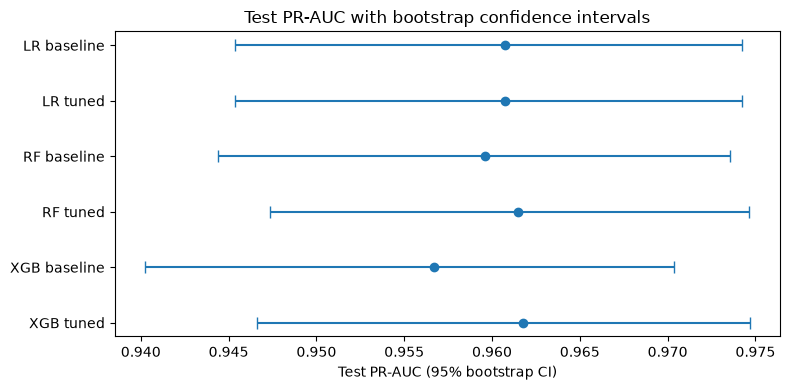

In [100]:
rng = np.random.default_rng(42)
n_boot = 1000
y_arr = y_test.to_numpy()
pos = np.flatnonzero(y_arr == 1)   # dropouts
neg = np.flatnonzero(y_arr == 0)   # graduates

metric_names = ["PR-AUC", "Precision", "Recall", "F1"]
boot = {name: {m: np.empty(n_boot) for m in metric_names} for name, *_ in models}

for b in range(n_boot):
    # Stratified bootstrap: resample dropouts and graduates separately
    idx = np.concatenate([rng.choice(pos, len(pos), replace=True),
                          rng.choice(neg, len(neg), replace=True)])
    yb = y_arr[idx]
    for name, _, prob, pred, _ in models:
        pb = np.asarray(pred)[idx]
        tp = np.sum((pb == 1) & (yb == 1))
        fp = np.sum((pb == 1) & (yb == 0))
        fn = np.sum((pb == 0) & (yb == 1))
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn)
        boot[name]["PR-AUC"][b]    = average_precision_score(yb, np.asarray(prob)[idx])
        boot[name]["Precision"][b] = p
        boot[name]["Recall"][b]    = r
        boot[name]["F1"][b]        = 2 * p * r / (p + r) if p + r else 0.0

# Point estimate [95% CI] for every model and metric
ci_table = pd.DataFrame({
    m: [f"{comparison.loc[name, 'Test PR-AUC' if m == 'PR-AUC' else m]:.3f} "
        f"[{np.percentile(boot[name][m], 2.5):.3f}, {np.percentile(boot[name][m], 97.5):.3f}]"
        for name, *_ in models]
    for m in metric_names
}, index=[name for name, *_ in models])
ci_table.index.name = "Model"
display(ci_table)

# Paired differences between the tuned models (same resamples, so the comparison is fair)
pairs = [("LR tuned", "RF tuned"), ("LR tuned", "XGB tuned"), ("RF tuned", "XGB tuned")]
for m in ["PR-AUC", "Recall"]:
    for a, b_ in pairs:
        diff = boot[a][m] - boot[b_][m]
        print(f"{a} minus {b_} ({m}): {diff.mean():+.3f}  "
              f"95% CI [{np.percentile(diff, 2.5):+.3f}, {np.percentile(diff, 97.5):+.3f}]  "
              f"{a} higher in {np.mean(diff > 0):.0%} of resamples")

# Plot: test PR-AUC with 95% CI error bars
names = [name for name, *_ in models]
point = comparison.loc[names, "Test PR-AUC"].to_numpy()
lo = np.array([np.percentile(boot[n]["PR-AUC"], 2.5) for n in names])
hi = np.array([np.percentile(boot[n]["PR-AUC"], 97.5) for n in names])
plt.figure(figsize=(8, 4))
plt.errorbar(point, names, xerr=[point - lo, hi - point], fmt="o", capsize=4)
plt.gca().invert_yaxis()
plt.xlabel("Test PR-AUC (95% bootstrap CI)")
plt.title("Test PR-AUC with bootstrap confidence intervals")
plt.tight_layout()
plt.show()

**Bootstrap results (tuned models, test set):**

| Model | PR-AUC [95% CI] | Recall [95% CI] | Precision | Flagged |
|---|---|---|---|---|
| Logistic regression | 0.961 [0.945, 0.974] | **0.933** [0.900, 0.963] | 0.845 | 297 |
| Random forest | 0.961 [0.947, 0.975] | 0.914 [0.877, 0.944] | 0.854 | 288 |
| XGBoost | 0.962 [0.947, 0.975] | 0.911 [0.874, 0.941] | **0.878** | 279 |

| Paired difference | PR-AUC [95% CI] | Recall [95% CI] |
|---|---|---|
| LR − RF | −0.001 [−0.007, +0.006] | +0.018 [−0.004, +0.041] |
| LR − XGB | −0.001 [−0.006, +0.004] | +0.022 [+0.004, +0.045] |
| RF − XGB | 0.000 [−0.004, +0.004] | +0.004 [−0.007, +0.019] |

The models are tied on PR-AUC. LR's higher recall comes from flagging more students, not better ranking. **Final model: tuned logistic regression**: as accurate as the others, most reliable at 90% recall, and the simplest to interpret.

With the selected model, output the 5 most significant factors:

In [101]:
import statsmodels.api as sm

# Training data exactly as the final model sees it (continuous columns scaled, 0/1 columns unchanged)
pre = lr_best.named_steps["preprocess"]
X_tr_model = pd.DataFrame(pre.transform(X_train), columns=pre.get_feature_names_out(), index=X_train.index).astype(float)

# Coefficients from the final model; p-values from the same model refitted in statsmodels
coef = pd.Series(lr_best.named_steps["model"].coef_[0], index=X_tr_model.columns)
logit = sm.Logit(y_train, sm.add_constant(X_tr_model)).fit(disp=0, maxiter=500)

factors = pd.DataFrame({
    "Coefficient": coef,
    "Odds ratio": np.exp(coef),
    "p-value": logit.pvalues.drop("const"),
    "Effect": np.where(coef > 0, "Raises dropout risk", "Lowers dropout risk"),
    "Per": ["1 std increase" if c in continuous else "yes vs no / vs reference" for c in coef.index],
})

# Top 5: significant at 5%, ranked by size of the effect
significant = factors[factors["p-value"] < 0.05]
top5 = significant.loc[significant["Coefficient"].abs().sort_values(ascending=False).index].head(5)
print(f"{len(significant)} of {len(factors)} features are significant (p < 0.05)")
top5.round(4)


17 of 55 features are significant (p < 0.05)


,Coefficient,Odds ratio,p-value,Effect,Per
Avg approval rate,-3.5137,0.0298,0.0000,Lowers dropout risk,1 std increase
Tuition fees up to date,-2.3869,0.0919,0.0000,Lowers dropout risk,yes vs no / vs reference
Course_9853,1.3785,3.9689,0.0003,Raises dropout risk,yes vs no / vs reference
Debtor,1.2607,3.5281,0.0000,Raises dropout risk,yes vs no / vs reference
Course_9238,-1.2250,0.2937,0.0013,Lowers dropout risk,yes vs no / vs reference


SHAP and permutation importance as another way to check: 

                               PR-AUC drop     Std
Avg approval rate                   0.3954  0.0277
Tuition fees up to date             0.0110  0.0012
Avg credited                        0.0091  0.0029
Avg enrolled                        0.0085  0.0020
Course_9853                         0.0028  0.0009
Change in grade                     0.0020  0.0011
Avg grade                           0.0019  0.0011
Debtor                              0.0016  0.0014
Application mode_Over 23            0.0012  0.0005
Father's qualification_Medium       0.0010  0.0007


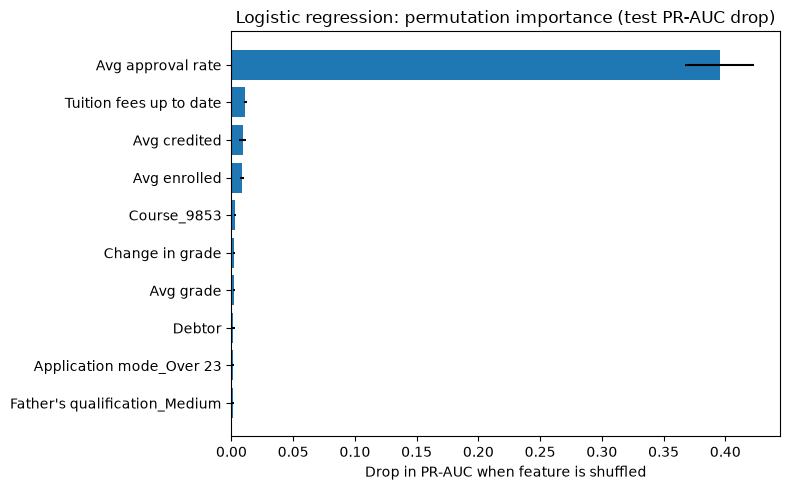

In [102]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    lr_best, X_test, y_test,
    scoring="average_precision",
    n_repeats=10, random_state=42, n_jobs=-1)

perm_importance = (pd.DataFrame({"PR-AUC drop": perm.importances_mean,
                                 "Std": perm.importances_std},
                                index=X_test.columns)
                     .sort_values("PR-AUC drop", ascending=False))
print(perm_importance.head(10).round(4))

top = perm_importance.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["PR-AUC drop"], xerr=top["Std"])
plt.title("Logistic regression: permutation importance (test PR-AUC drop)")
plt.xlabel("Drop in PR-AUC when feature is shuffled")
plt.tight_layout()
plt.show()


Background dataset has 2782 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2782 when initializing the masker.


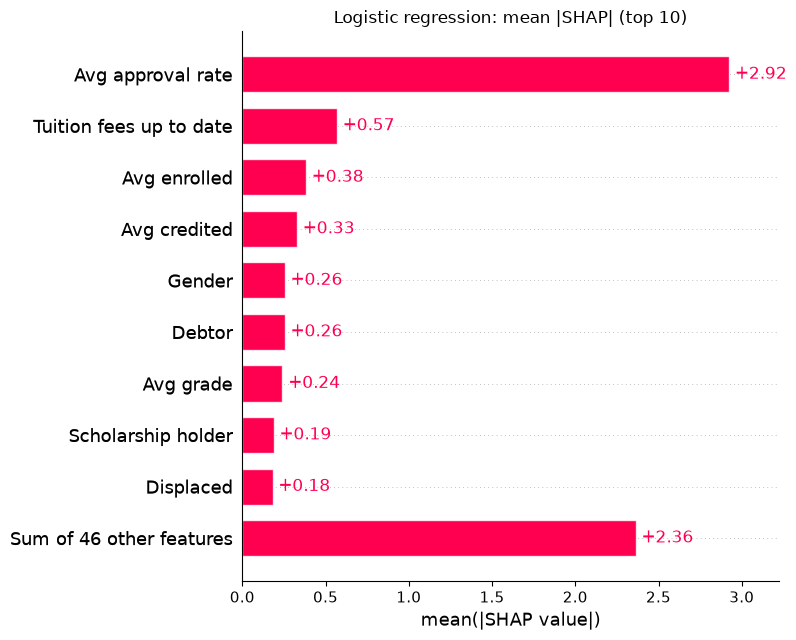

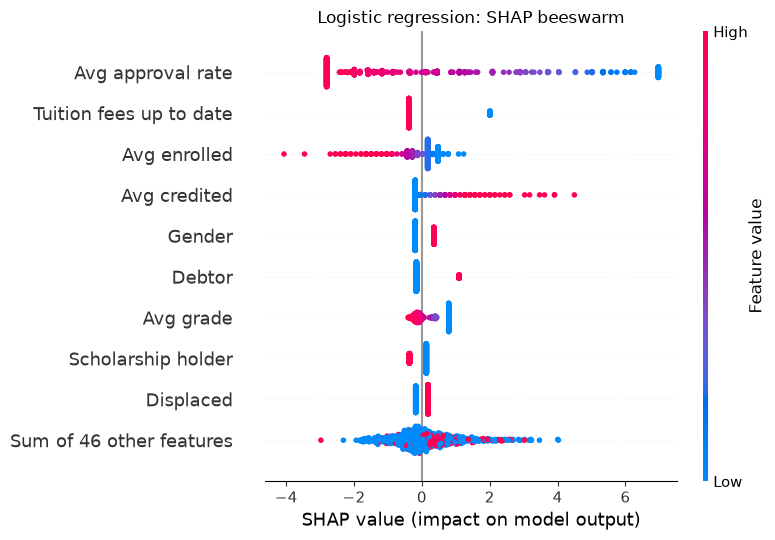

,Coefficient rank,Permutation rank,SHAP rank,Significant (p<0.05)
Avg approval rate,1,1,1,True
Tuition fees up to date,2,2,2,True
Avg enrolled,11,4,3,True
Avg credited,10,3,4,True
Gender,17,31,5,True
Debtor,4,8,6,True
Avg grade,26,7,7,False
Scholarship holder,19,12,8,True
Displaced,23,54,9,True
Father's qualification_Medium,20,10,10,True


In [103]:
import shap

# Test data exactly as the model sees it (continuous columns scaled, 0/1 columns unchanged)
X_te_model = pd.DataFrame(pre.transform(X_test), columns=pre.get_feature_names_out(), index=X_test.index).astype(float)

explainer = shap.LinearExplainer(lr_best.named_steps["model"], X_tr_model)   # training data as the background
shap_values = explainer(X_te_model)                                          # values are in log-odds of dropout

# 1) Overall importance: mean |SHAP| per feature
shap.plots.bar(shap_values, max_display=10, show=False)
plt.title("Logistic regression: mean |SHAP| (top 10)")
plt.tight_layout(); plt.show()

# 2) Direction: red = high feature value, blue = low; right = pushes toward dropout
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title("Logistic regression: SHAP beeswarm")
plt.tight_layout(); plt.show()

# 3) Compare the three methods: rank of each feature (1 = most important)
shap_rank = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_te_model.columns)
ranks = pd.DataFrame({
    "Coefficient rank": factors["Coefficient"].abs().rank(ascending=False),
    "Permutation rank": perm_importance["PR-AUC drop"].rank(ascending=False),
    "SHAP rank":        shap_rank.rank(ascending=False),
    "Significant (p<0.05)": factors["p-value"] < 0.05,
}).astype({"Coefficient rank": int, "Permutation rank": int, "SHAP rank": int})
ranks.sort_values("SHAP rank").head(10)


Conclusion:
Dropout is predicted almost entirely by first-year academic progress, with financial status as a clear second factor. The three tuned models are statistically tied (PR-AUC about 0.96), so tuned logistic regression was chosen for simplicity and interpretability. At a threshold set to catch 90% of dropouts, it caught 251 of 269 on the test set (recall 0.93) while flagging 43% of students. All three importance methods rank avg approval rate first and tuition-fee status second. Demographic factors such as gender add little predictive value. A practical early-warning rule follows directly: students passing few of their first-year units, or falling behind on fees, should be contacted first.
Limitations:
1) This is only based on one institution, and timing of the fee data is undocumented.
2) It's hard to put other factors like mental health or institution prestige into numerical variables. 